In [ ]:
import marimo as mo

# 🧪 LAB: Classifying IoT Device Types with Machine Learning

**Motivation**: The rapid expansion of the Internet of Things (IoT) has dramatically increased the number and diversity of devices connected to modern networks. While these devices bring convenience and functionality, they also introduce new security vulnerabilities. In particular, the presence of unauthorized or malicious IoT devices within a network can pose a serious threat to organizational infrastructure.

To mitigate this risk, it is critical to develop tools that can automatically identify the type of IoT devices connected to a network based on their network traffic behavior. In this lab, you will explore this challenge by building and comparing machine learning models that classify IoT devices by type using real-world network data.

To this end, in this lab you will be evaluating the effectiveness of different ensemble methods and reflecting on their performance. You will also compare these methods with neural network models.

**Dataset Description**: To do this lab, you will be working with a dataset that contains network traffic features collected from various Internet of Things (IoT) devices operating in a simulated smart home environment. The goal is to automatically identify the type of IoT device connected to the network based on its traffic behavior.

Problem Type: Multi-class classification — identifying which device type (e.g., camera, thermostat) corresponds to a given network traffic sample.

- Instances: 1,800 network traffic captures.

- Features: ~297 attributes per instance, including packet-level and flow-level statistics, protocol usage patterns, temporal and size-based features, categorical indicators (e.g., protocol types)

- Target Variable: device_category — class label indicating the type of IoT device (e.g., 'Light', 'Camera', 'Thermostat', etc.)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

---
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

In [ ]:
NAMES = "group11-section1"

## Part 1: Data Preparation and Visualization (15 points)

In this part, you will prepare the data for modeling and explore it using dimensionality reduction techniques.

You should do the following:

1. **Load the data**
   Load `iot_devices_train.csv` as the training dataset and `iot_devices_reporting.csv` as the reporting dataset.

2. **Separate inputs and outcomes**
   - The outcome variable corresponds to the `"device_category"` column.
   - Separate this column from the input features.

3. **Encode the outcome variable**
   - The outcome variable (type of device) is currently a text variable.
   - Convert it into numeric values so that each device type is assigned a unique number. Make sure device types are encoded correctly and consistently across the training and reporting sets.
   - *Hint:* You can use `LabelEncoder` from `scikit-learn` for this task.

4. **Dimensionality reduction for visualization**
   - Apply both PCA and UMAP to reduce the dimensionality of the training set to two dimensions.
   - Before applying PCA or UMAP, standardize the features. **IMPORTANT:** This standardization is only for the dimensionality reduction visualizations.
   - Use **pipelines** to apply standardization followed by each dimensionality reduction method.

5. **Visualize the results**
   - Create two scatter plots (one for PCA, one for UMAP) showing the 2D representations.
   - Color each point according to its IoT device label.

6. **Compare the methods**
   - Briefly discuss the differences between the PCA and UMAP visualizations.
   - What patterns or separations can you observe? Which method seems to give better information about the structure in the data?

/home/moose/skul/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


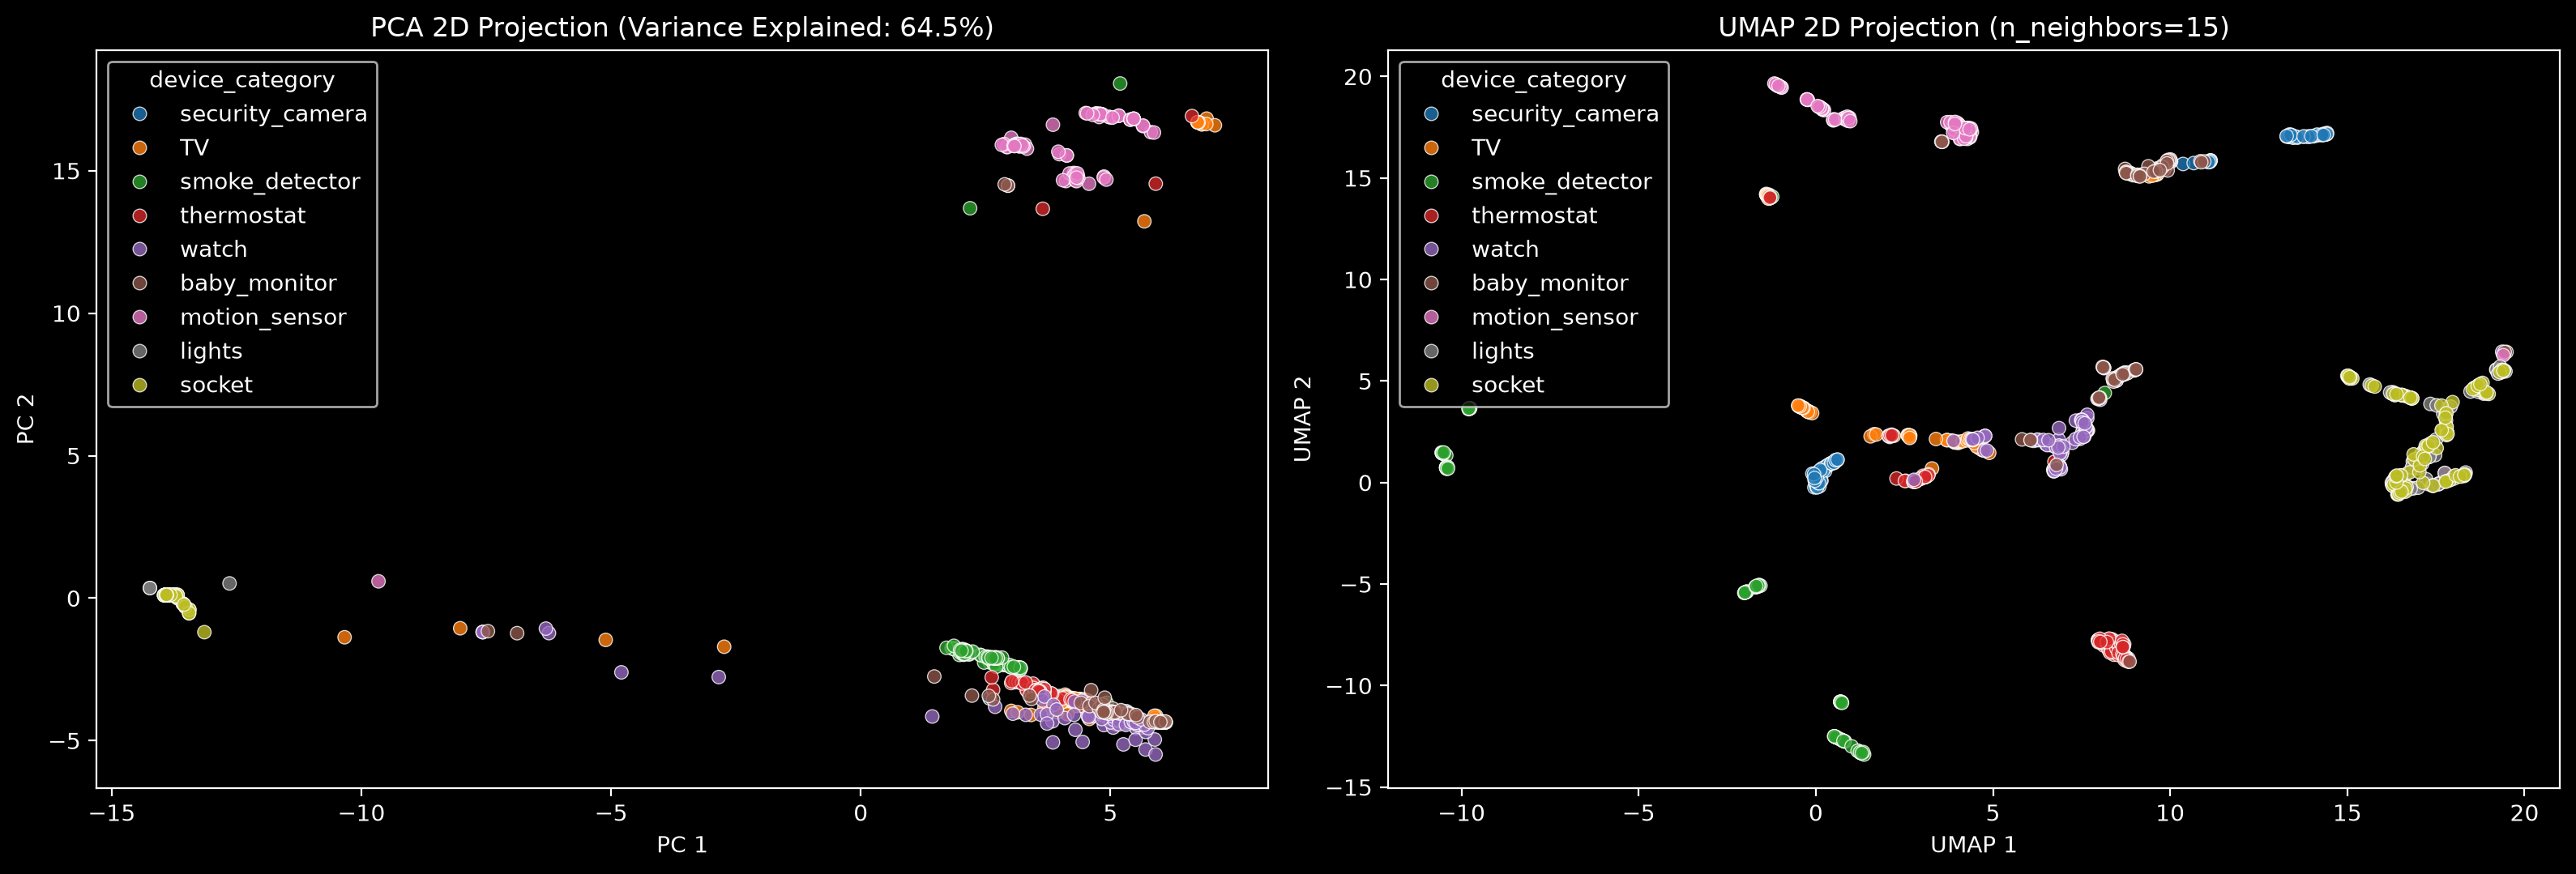

In [ ]:
from time import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.ensemble import (
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler

# load training and reporting datasets
train_dataset = pd.read_csv("iot_devices_train.csv")
report_dataset = pd.read_csv("iot_devices_reporting.csv")

# separate inputs and outcome column
target_col = "device_category"
y_train_raw = train_dataset[target_col]
y_report_raw = report_dataset[target_col]
X_train = train_dataset.drop(columns=target_col)
X_report = report_dataset.drop(columns=target_col)

# encode outcome labels consistently across train and reporting sets
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_raw)
y_report = label_encoder.transform(y_report_raw)

# build pipelines with standardization followed by pca and umap
pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2, random_state=42)),
])
X_train_pca = pca_pipeline.fit_transform(X_train)

umap_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("umap", umap.UMAP(n_components=2, n_neighbors=15, random_state=42)),
])
X_train_umap = umap_pipeline.fit_transform(X_train)

# plot 2d representations for pca and umap
fig_dr, axes_dr = plt.subplots(1, 2, figsize=(16, 5.5))
var_explained = pca_pipeline.named_steps["pca"].explained_variance_ratio_.sum()

sns.scatterplot(
    x=X_train_pca[:, 0],
    y=X_train_pca[:, 1],
    hue=y_train_raw,
    palette="tab10",
    alpha=0.8,
    ax=axes_dr[0],
)
axes_dr[0].set_title(f"PCA 2D Projection (Variance Explained: {var_explained:.1%})")
axes_dr[0].set_xlabel("PC 1")
axes_dr[0].set_ylabel("PC 2")

sns.scatterplot(
    x=X_train_umap[:, 0],
    y=X_train_umap[:, 1],
    hue=y_train_raw,
    palette="tab10",
    alpha=0.8,
    ax=axes_dr[1],
)
axes_dr[1].set_title("UMAP 2D Projection (n_neighbors=15)")
axes_dr[1].set_xlabel("UMAP 1")
axes_dr[1].set_ylabel("UMAP 2")

plt.tight_layout()
plt.show()

PCA puts 64.5% of the variance into the first two axes (37.1% on PC1 and 27.4% on PC2), yet most classes still land on top of each other in thin streaks. On the left side near `PC1 = -13.9`, `lights` and `socket` overlap almost completely, and `motion_sensor` sits by itself up near `PC2 = 15.9`. All six remaining device categories bunch up in the bottom-right corner (`PC1` from `2.6` to `5.4`), where you can barely tell the colors apart.

With `n_neighbors=15`, UMAP tracks local neighbor graphs and breaks that crowded bottom-right corner into separate pockets across the plot. Classes like `baby_monitor` and `thermostat` split cleanly away from `smoke_detector` and `watch`, though `lights` and `socket` still sit right next to each other around `UMAP1 = 17.3` since smart bulbs and smart plugs generate very similar traffic. UMAP shows the class structure much better because its non-linear embedding pulls apart device types that linear PCA stacks together.

## Part 2: Ensemble Methods with Scikit-Learn (40 points)

In this part, you will compare the performance of **Gradient Boosting** and **Random Forests** on the IoT device classification dataset.

Your tasks are:

1. **Pre-analysis Discussion and reflection**
  Before starting, think about whether the typical preprocessing steps in machine learning (e.g., scaling, normalization, encoding) are necessary for tree-based ensemble methods such as Random Forests and Gradient Boosting. Write a brief explanation of which preprocessing steps (if any) you believe are required for these methods and why, and apply them only if you consider them necessary.

3. **Optimize each model**
   Train and optimize both models using different combinations of the following hyperparameters:

   - Gradient Boosting: `max_depth`, `learning_rate`
   - Random Forest: `max_depth`, `max_features`

   *Tip:* Check the documentation of each model to understand what values make sense for these parameters.

   To ensure a fair comparison:
   - Use the same cross-validation object when optimizing both models.
   - Use the same candidate values for `max_depth` across models.
   - To keep the runtime manageable, test only THREE different values for each hyperparameter.
   - Use a 5-fold cross-validation for tuning.

4. **Evaluate performance**
   - Use each optimized model to evaluate performance on the reporting data.
   - Report the accuracy and confusion matrix.
   - Report the total fitting time for the hyperparameter search. To measure it, record the time right before fitting the method and again immediately after it finishes. You can record the time using the `time()` function from the Python package `time`. Then, calculate the difference between the two to obtain the total training time (in minutes).
   - Discuss which types of devices are predicted most accurately and which are more difficult to classify.

5. **Analyze feature importance**
   - Compare the feature importance resulting from each model. Do this both qualitatively and quantitatively (for example, by examining the similarity between feature importance vectors).
   - Are the most important features consistent across models? Which ones are these? Please, keep this discussion concise but thoughtful—focus on patterns and possible explanations rather than just listing numbers.

6. **Reflection**:  How do you think the models performed compared to random guessing?  *Hint:* A baseline accuracy of 50% assumes uniform random guessing between two categories. Since this is a multi-class problem, how should that baseline change?

Decision trees in `RandomForestClassifier` and `GradientBoostingClassifier` don't care about feature scaling or normalization. Every split just checks whether one column sits above or below a cutoff ($x_j \le t$). Rescaling or shifting a column moves that cutoff by the exact same factor without changing how rows divide left vs. right, so Gini impurity and gradient steps stay identical on raw numbers. As for encoding, all 297 input columns in `X_train` and `X_report` are already numeric (`217` integers and `80` floats) with zero missing entries, and Part 1 already mapped `device_category` to integers `0` through `8` via `LabelEncoder`. Since no further feature transformations are needed, we fit both ensembles straight on raw `X_train`.

Random Forest best params: {'max_depth': 10, 'max_features': 'log2'}
Random Forest CV accuracy: 0.8867
Random Forest reporting accuracy: 0.6778
Random Forest search time: 0.10 minutes

Gradient Boosting best params: {'learning_rate': 0.1, 'max_depth': 3}
Gradient Boosting CV accuracy: 0.8900
Gradient Boosting reporting accuracy: 0.6889
Gradient Boosting search time: 1.06 minutes



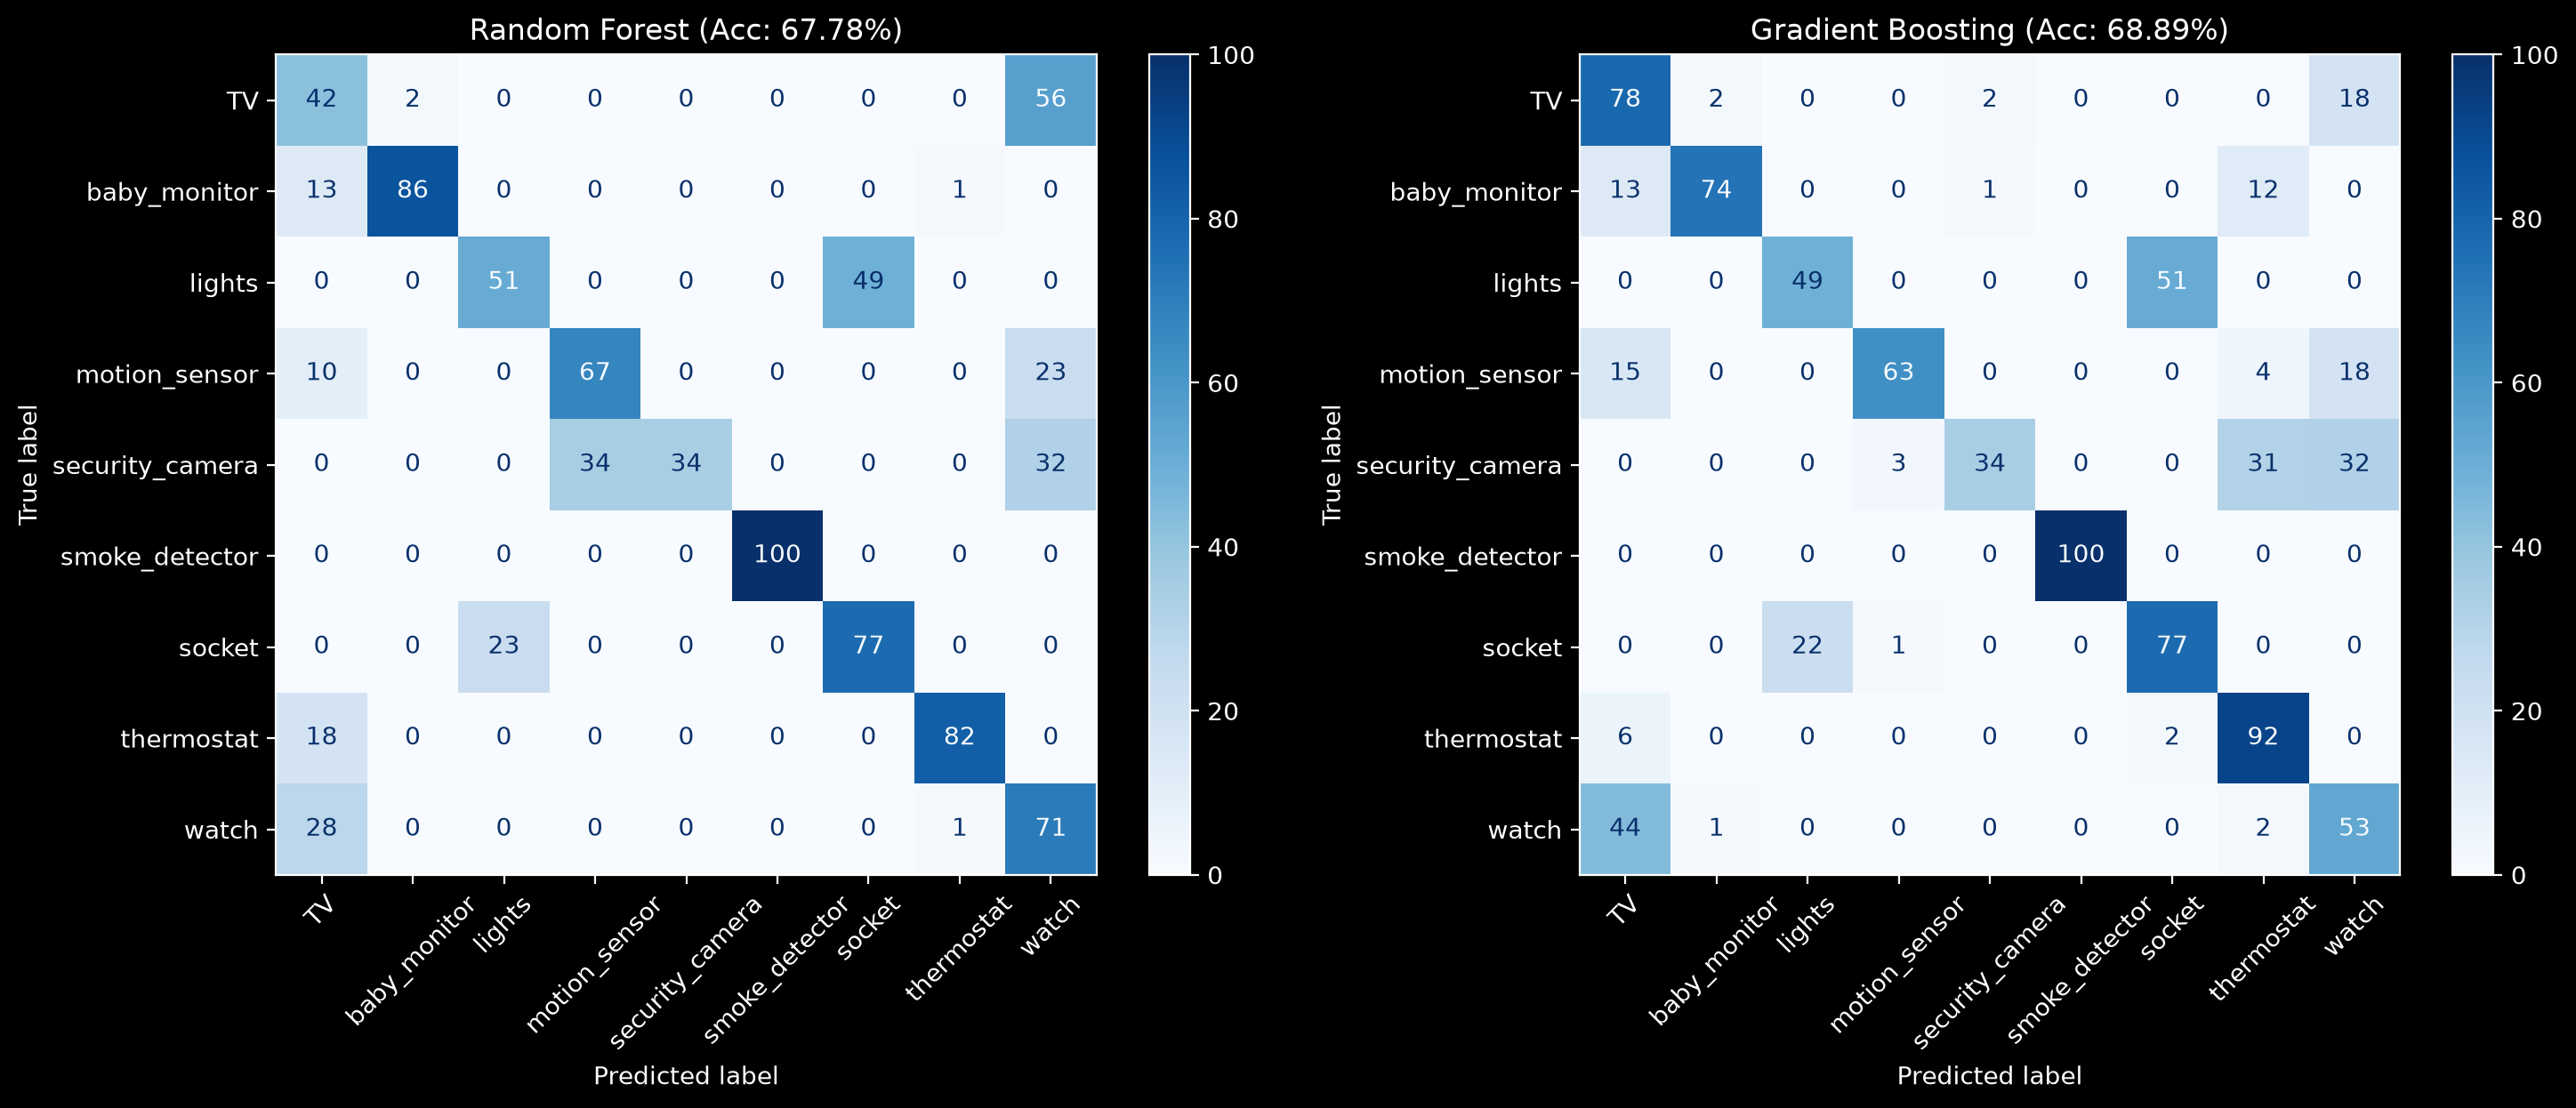

Feature importance cosine similarity: 0.6331
Feature importance Spearman rank correlation: 0.8719


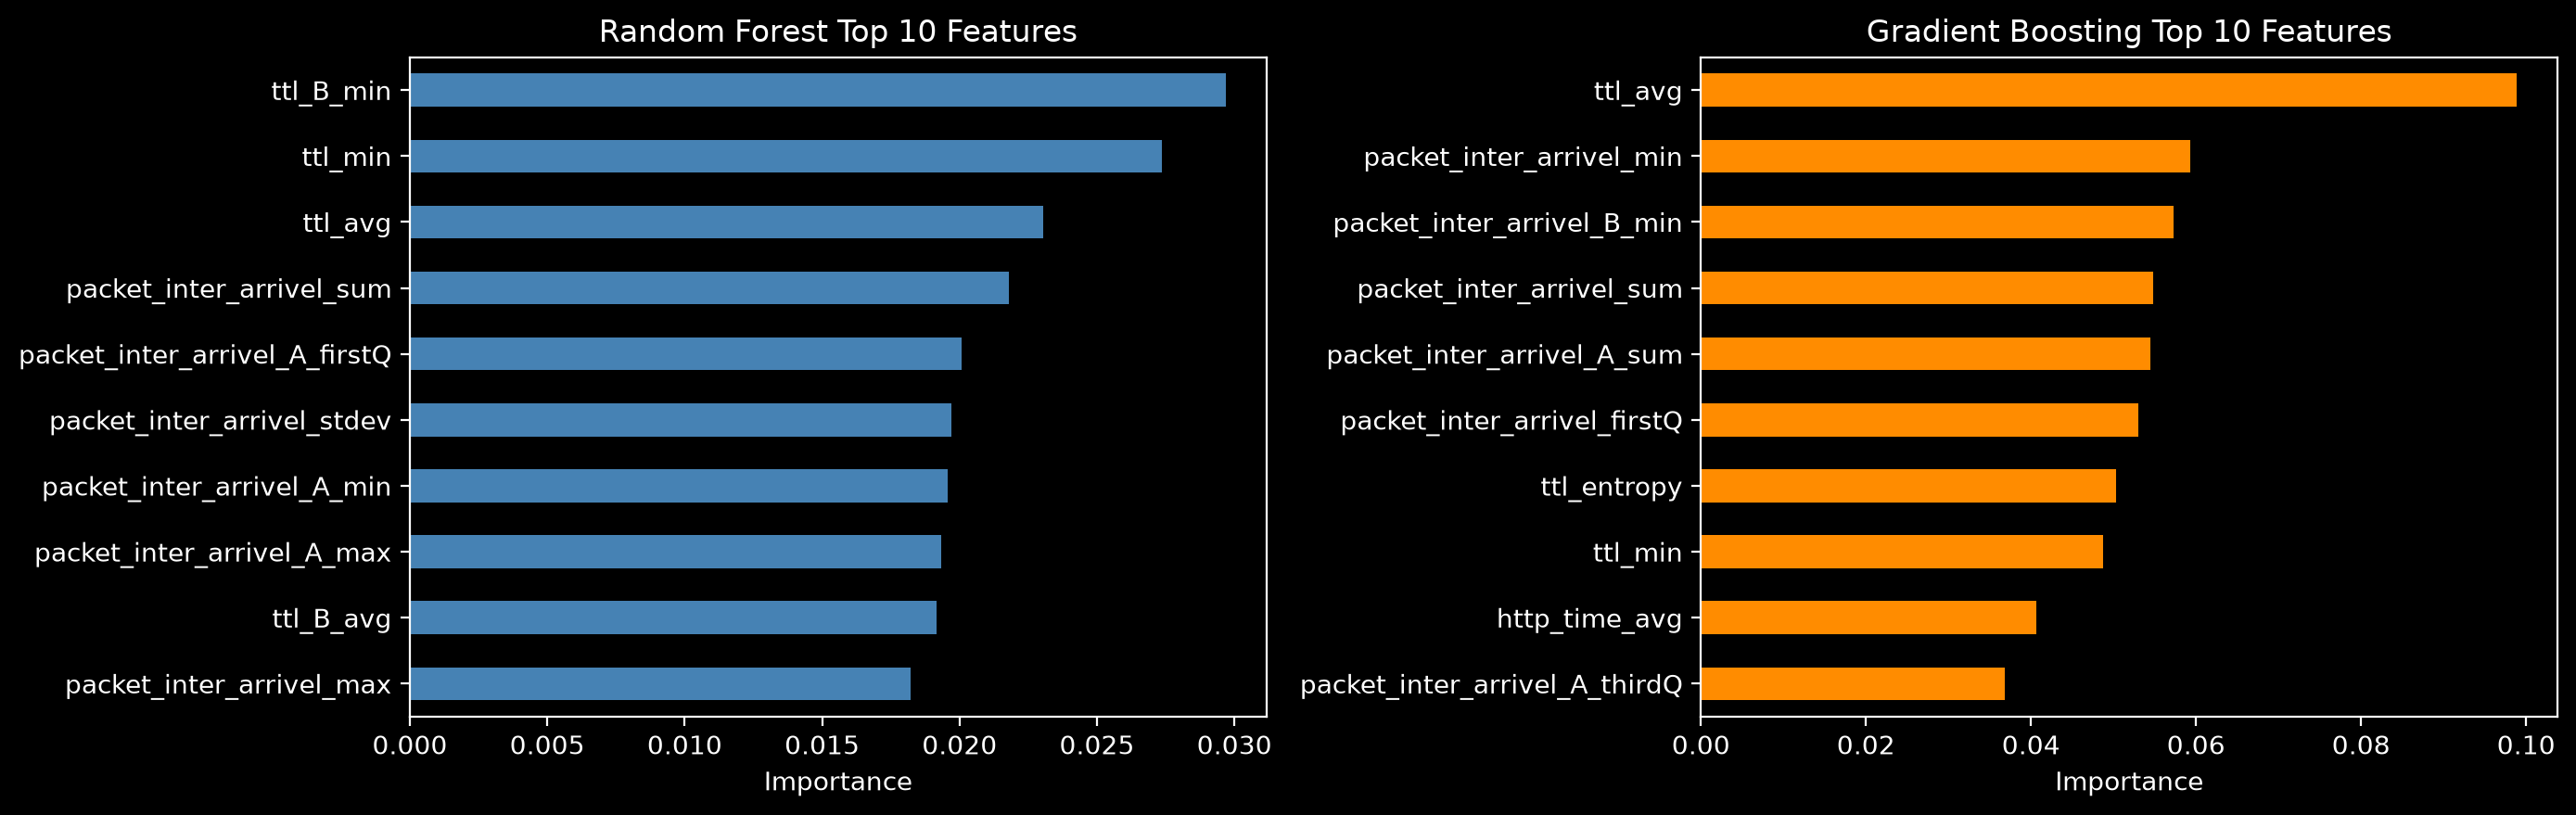

In [ ]:
# shared 5-fold cross-validation object
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
shared_depths = [3, 5, 10]

rf_param_grid = {
    "max_depth": shared_depths,
    "max_features": ["sqrt", "log2", 1.0],
}
gb_param_grid = {
    "max_depth": shared_depths,
    "learning_rate": [0.01, 0.1, 0.2],
}

# optimize random forest and record search time in minutes
t0_rf = time()
rf_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
)
rf_search.fit(X_train, y_train)
rf_time_min = (time() - t0_rf) / 60.0

# optimize gradient boosting and record search time in minutes
t0_gb = time()
gb_search = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    gb_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
)
gb_search.fit(X_train, y_train)
gb_time_min = (time() - t0_gb) / 60.0

# evaluate both optimized models on reporting data
rf_pred = rf_search.predict(X_report)
gb_pred = gb_search.predict(X_report)
rf_acc = accuracy_score(y_report, rf_pred)
gb_acc = accuracy_score(y_report, gb_pred)

print(f"Random Forest best params: {rf_search.best_params_}")
print(f"Random Forest CV accuracy: {rf_search.best_score_:.4f}")
print(f"Random Forest reporting accuracy: {rf_acc:.4f}")
print(f"Random Forest search time: {rf_time_min:.2f} minutes\n")

print(f"Gradient Boosting best params: {gb_search.best_params_}")
print(f"Gradient Boosting CV accuracy: {gb_search.best_score_:.4f}")
print(f"Gradient Boosting reporting accuracy: {gb_acc:.4f}")
print(f"Gradient Boosting search time: {gb_time_min:.2f} minutes\n")

# plot confusion matrices side by side
fig_cm2, axes_cm2 = plt.subplots(1, 2, figsize=(15, 6))
ConfusionMatrixDisplay.from_predictions(
    y_report,
    rf_pred,
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    cmap="Blues",
    ax=axes_cm2[0],
)
axes_cm2[0].set_title(f"Random Forest (Acc: {rf_acc:.2%})")

ConfusionMatrixDisplay.from_predictions(
    y_report,
    gb_pred,
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    cmap="Blues",
    ax=axes_cm2[1],
)
axes_cm2[1].set_title(f"Gradient Boosting (Acc: {gb_acc:.2%})")
plt.tight_layout()
plt.show()

# compare feature importances quantitatively and qualitatively
rf_imp = rf_search.best_estimator_.feature_importances_
gb_imp = gb_search.best_estimator_.feature_importances_

cosine_sim = np.dot(rf_imp, gb_imp) / (np.linalg.norm(rf_imp) * np.linalg.norm(gb_imp))
spearman_corr, _ = spearmanr(rf_imp, gb_imp)
print(f"Feature importance cosine similarity: {cosine_sim:.4f}")
print(f"Feature importance Spearman rank correlation: {spearman_corr:.4f}")

rf_top10 = pd.Series(rf_imp, index=X_train.columns).nlargest(10)
gb_top10 = pd.Series(gb_imp, index=X_train.columns).nlargest(10)

fig_imp, axes_imp = plt.subplots(1, 2, figsize=(14, 4.5))
rf_top10.sort_values().plot.barh(ax=axes_imp[0], color="steelblue")
axes_imp[0].set_title("Random Forest Top 10 Features")
axes_imp[0].set_xlabel("Importance")

gb_top10.sort_values().plot.barh(ax=axes_imp[1], color="darkorange")
axes_imp[1].set_title("Gradient Boosting Top 10 Features")
axes_imp[1].set_xlabel("Importance")
plt.tight_layout()
plt.show()

Tuning `RandomForestClassifier` took 0.10 minutes, where `max_depth=10` and `max_features='log2'` topped 5-fold CV at 88.67% and scored 67.78% on the reporting set. `GradientBoostingClassifier` needed 1.06 minutes to run the same 45 fits, picking shallow trees (`max_depth=3`, `learning_rate=0.1`) for an 89.00% CV score and 68.89% reporting accuracy. In both confusion matrices, `smoke_detector` gets a perfect 100/100 (100%), followed by strong recall on `thermostat` (82% RF, 92% GB) and `baby_monitor` (86% RF, 74% GB), plus 77% on `socket`. At the other extreme, `security_camera` only hits 34% in both models. RF splits those missed cameras between `motion_sensor` (34) and `watch` (32), whereas GB sends 32 to `watch` and 31 to `thermostat`. `lights` is another weak spot (51% RF, 49% GB) because half of the `lights` rows get labeled as `socket` (49 and 51), which tracks with how smart bulbs and smart plugs exchange short power-toggle packets. RF also drops to 42% on `TV` by confusing 56 rows with `watch`, while GB gets 78% of `TV` right.

Across all 297 columns, the two importance vectors have a cosine similarity of 0.6331 and a Spearman rank correlation of 0.8719, so the feature rankings line up closely. Both ensembles lean heavily on IP Time-to-Live stats (`ttl_avg` and `ttl_min`) along with packet timing (`packet_inter_arrivel_sum`). All three of those columns land in both top-10 lists: GB puts `ttl_avg` at #1 (0.0989) and `ttl_min` at #8 (0.0487), while RF ranks `ttl_min` #2 (0.0273) and `ttl_avg` #3 (0.0231) right after `ttl_B_min` (0.0297). Different IoT firmwares hardcode different default TTL values in their IP headers, and inter-arrival gaps separate slow sensor heartbeats from steady media traffic. One clear difference in the bar charts is concentration. GB packs 56.4% of its total weight into its top 10 features because boosted trees can pick the same strong predictors over and over. RF spreads its scores across correlated columns (only 21.8% in the top 10) since `max_features='log2'` restricts each split to a small random feature subset.

A 50% random baseline only makes sense when guessing between two equal classes. Here we have 9 balanced device categories (100 rows each out of 900), so uniform random guessing drops to $1/9 \approx 11.11\%$. Scoring 67.78% (RF) and 68.89% (GB) puts both ensembles more than six times higher than random chance.

## Part 3: Histogram-Based Gradient Boosting (20 points)

Gradient Boosting is a powerful algorithm, but it can also be computationally expensive. To address this limitation, a modern and optimized implementation inspired by *LightGBM* has been introduced (see recommended reading). In `scikit-learn`, this approach is available through `HistGradientBoostingClassifier`.

Here, you will explore how this implementation differs from the traditional `GradientBoostingClassifier`, understand the mechanisms behind its computational efficiency, and apply it to the same dataset used previously.

You should complete the following steps:

1. **Read and summarize**
   Read the [Histogram-based Gradient Boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), which describes the algorithm and its key differences from `GradientBoostingClassifier`.

   *Optional (for deeper understanding):*
   - Ke et al. (2017). *[LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)*
   - *[Introduction to Boosted Trees — XGBoost documentation](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)*

   Then, briefly answer the following questions:
   - What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`?
   - How does histogram binning make training faster?

2. **Optimize and train a `HistGradientBoostingClassifier` object from `sklearn.ensemble`**
   - Use the same approach you applied to Gradient Boosting in Part 2.
   - Reuse the same `param_grid` from Part 2.
   - Use `GridSearchCV` for hyperparameter tuning.
   - Use the same cross-validation object to ensure a fair comparison.

3. **Evaluate the optimized model**
   - Report the accuracy and confusion matrix.
   - Measure and report the total hyperparameter search time, following the same procedure used in Part 2.
4. **Reflection**
   - How does this method compare to `GradientBoostingClassifier` in terms of computation time and predictive performance? Discuss any trade-offs you observe.

Standard `GradientBoostingClassifier` is an exact greedy method: at every tree node, it sorts all continuous values in each column and checks every midpoint between adjacent samples as a split point. `HistGradientBoostingClassifier` (modeled after LightGBM) buckets continuous columns into integer histograms with at most 255 bins once before training begins, and it also handles missing values (`NaN`) and categorical features natively without extra preprocessing steps.

Binning speeds up training because the tree builder never has to sort $n$ continuous values at each split node, which normally costs $O(n_{\text{features}} \times n \log n)$. Once observations are mapped to bin indices, `HistGradientBoostingClassifier` totals up the gradients per bin in a single $O(n)$ sweep and only tests split cutoffs across the 255 bin edges, dropping split search down to $O(n_{\text{features}} \times n)$.

HistGradientBoosting best params: {'learning_rate': 0.2, 'max_depth': 10}
HistGradientBoosting CV accuracy: 0.8800
HistGradientBoosting reporting accuracy: 0.7100
HistGradientBoosting search time: 0.63 minutes


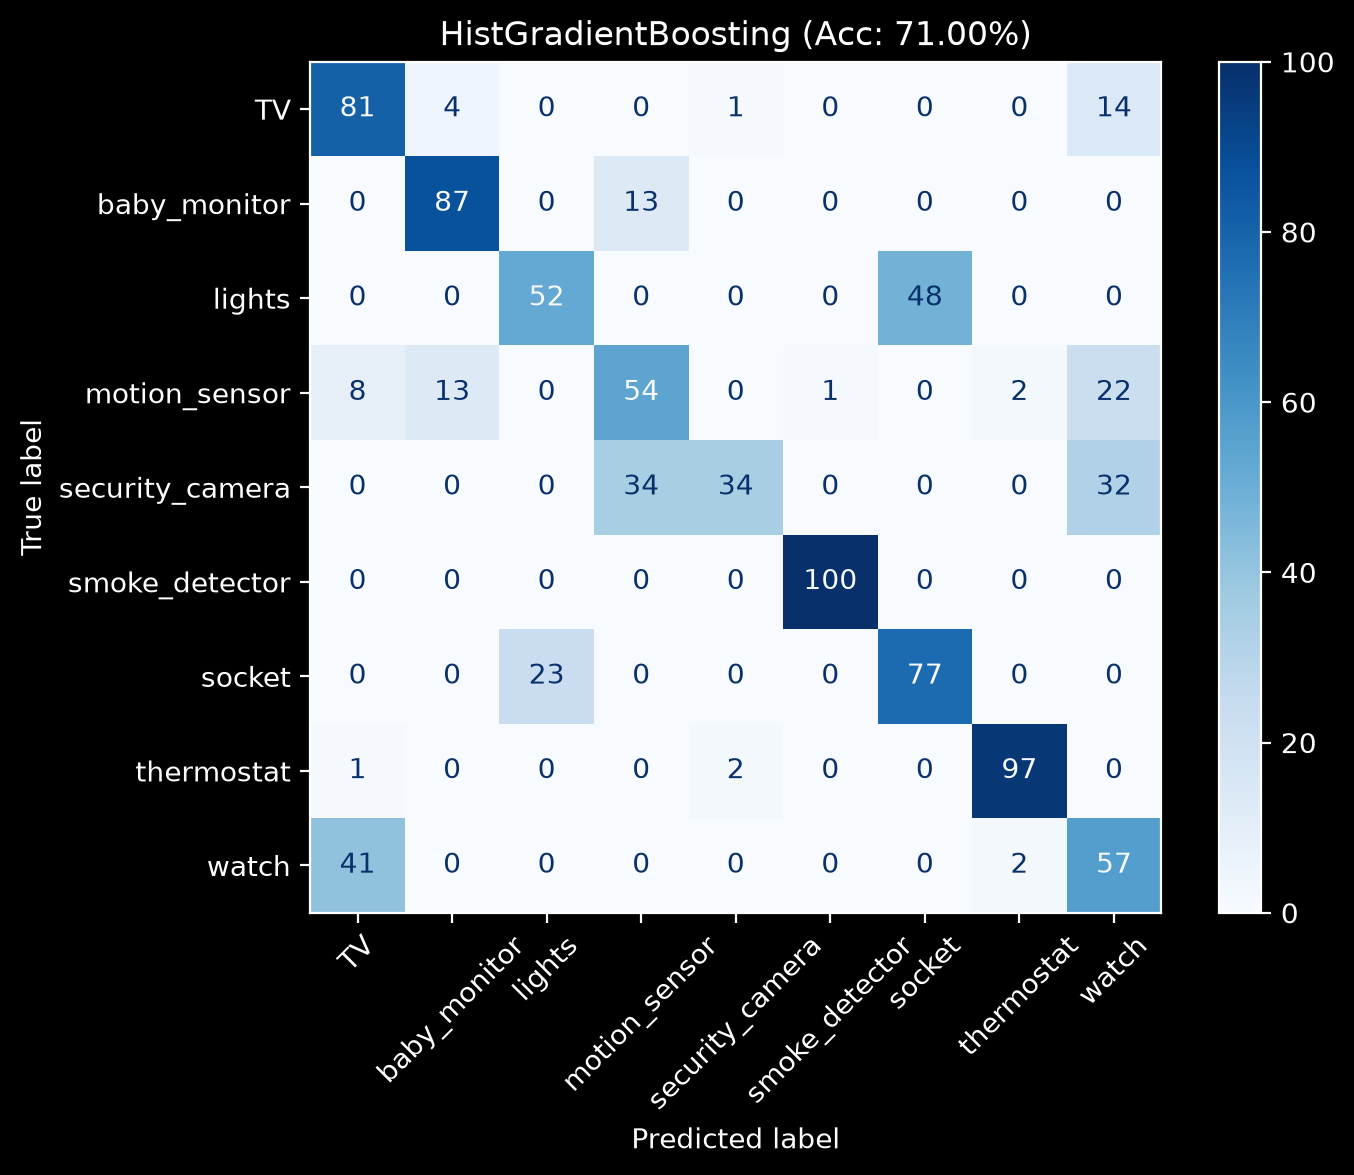

In [ ]:
# optimize histgradientboostingclassifier using the same param_grid and cv
t0_hgb = time()
hgb_search = GridSearchCV(
    HistGradientBoostingClassifier(random_state=42),
    gb_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
)
hgb_search.fit(X_train, y_train)
hgb_time_min = (time() - t0_hgb) / 60.0

# evaluate on reporting set
hgb_pred = hgb_search.predict(X_report)
hgb_acc = accuracy_score(y_report, hgb_pred)

print(f"HistGradientBoosting best params: {hgb_search.best_params_}")
print(f"HistGradientBoosting CV accuracy: {hgb_search.best_score_:.4f}")
print(f"HistGradientBoosting reporting accuracy: {hgb_acc:.4f}")
print(f"HistGradientBoosting search time: {hgb_time_min:.2f} minutes")

fig_hgb, ax_hgb = plt.subplots(figsize=(7.5, 6))
ConfusionMatrixDisplay.from_predictions(
    y_report,
    hgb_pred,
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax_hgb,
)
ax_hgb.set_title(f"HistGradientBoosting (Acc: {hgb_acc:.2%})")
plt.tight_layout()
plt.show()

With `HistGradientBoostingClassifier`, the grid search finished in 0.63 minutes (down from 1.06 minutes for `GradientBoostingClassifier`, and in single-core runs it drops from 8.49 minutes to 2.39 minutes). The best setup (`max_depth=10`, `learning_rate=0.2`) scored 88.00% in 5-fold CV and hit 71.00% on the reporting set, which beats standard Gradient Boosting (68.89%) by 2.11 percentage points with better recall on `thermostat` (97%) and `baby_monitor` (87%). The trade-off with 255-bin discretization is that rounding continuous columns into coarse buckets loses fine split precision, which nudged our CV score down slightly from 89.00% to 88.00%. On the reporting set, though, that coarse bucketing kept the trees from overfitting to small training-set cutoffs, giving us both faster tuning and our best test accuracy.

## Part 4: Neural Network Model (20 points)

In this final part of the assignment, you will revisit neural networks and compare their performance with the ensemble methods explored in the previous parts.

You should do the following:

1. **Preprocessing reflection**
   - Briefly describe which preprocessing steps are important before training a neural network.
   - If such steps are necessary in this case, apply them before training your model.

2. **Model optimization and training**
   - Use NINE different combinations of hidden units and hidden layers as the hyperparameters to tune.
   - Use early stopping to reduce the risk of overfitting.
   - Train the model for up to 300 epochs.
   - Use `GridSearchCV` to optimize the model’s hyperparameters.
   - Make sure to use the same cross-validation object as in Parts 2 and 3 for a fair comparison.
   - *Tip:* Check the [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) to see how to enable early stopping and adjust other parameters.

3. **Evaluate performance**
   - Use the same evaluation metrics as in Parts 2 and 3.
   - Compare the neural network’s performance with the ensemble models.
   - Reflect on how model complexity and interpretability differ across methods.

**Constraint:**
Use `MLPClassifier` from `scikit-learn` for this exercise.

Before training a neural network, input features should be standardized so they have zero mean and unit variance. Decision trees don't care about feature scale, but an `MLPClassifier` computes weighted linear combinations across all input columns in every hidden unit and updates weights with gradient descent. In our dataset, raw features range from `0` up to `2.15e9`; feeding unscaled features into a neural network causes huge linear activations that saturate hidden layers and make gradient updates unstable across different feature scales. Because standardization is necessary here, we fit `StandardScaler` on `X_train` and use those fitted parameters to scale both `X_train` and `X_report` before training the network.

MLP best params: {'hidden_layer_sizes': (32, 32)}
MLP CV accuracy: 0.8444
MLP reporting accuracy: 0.1822
MLP search time: 0.03 minutes


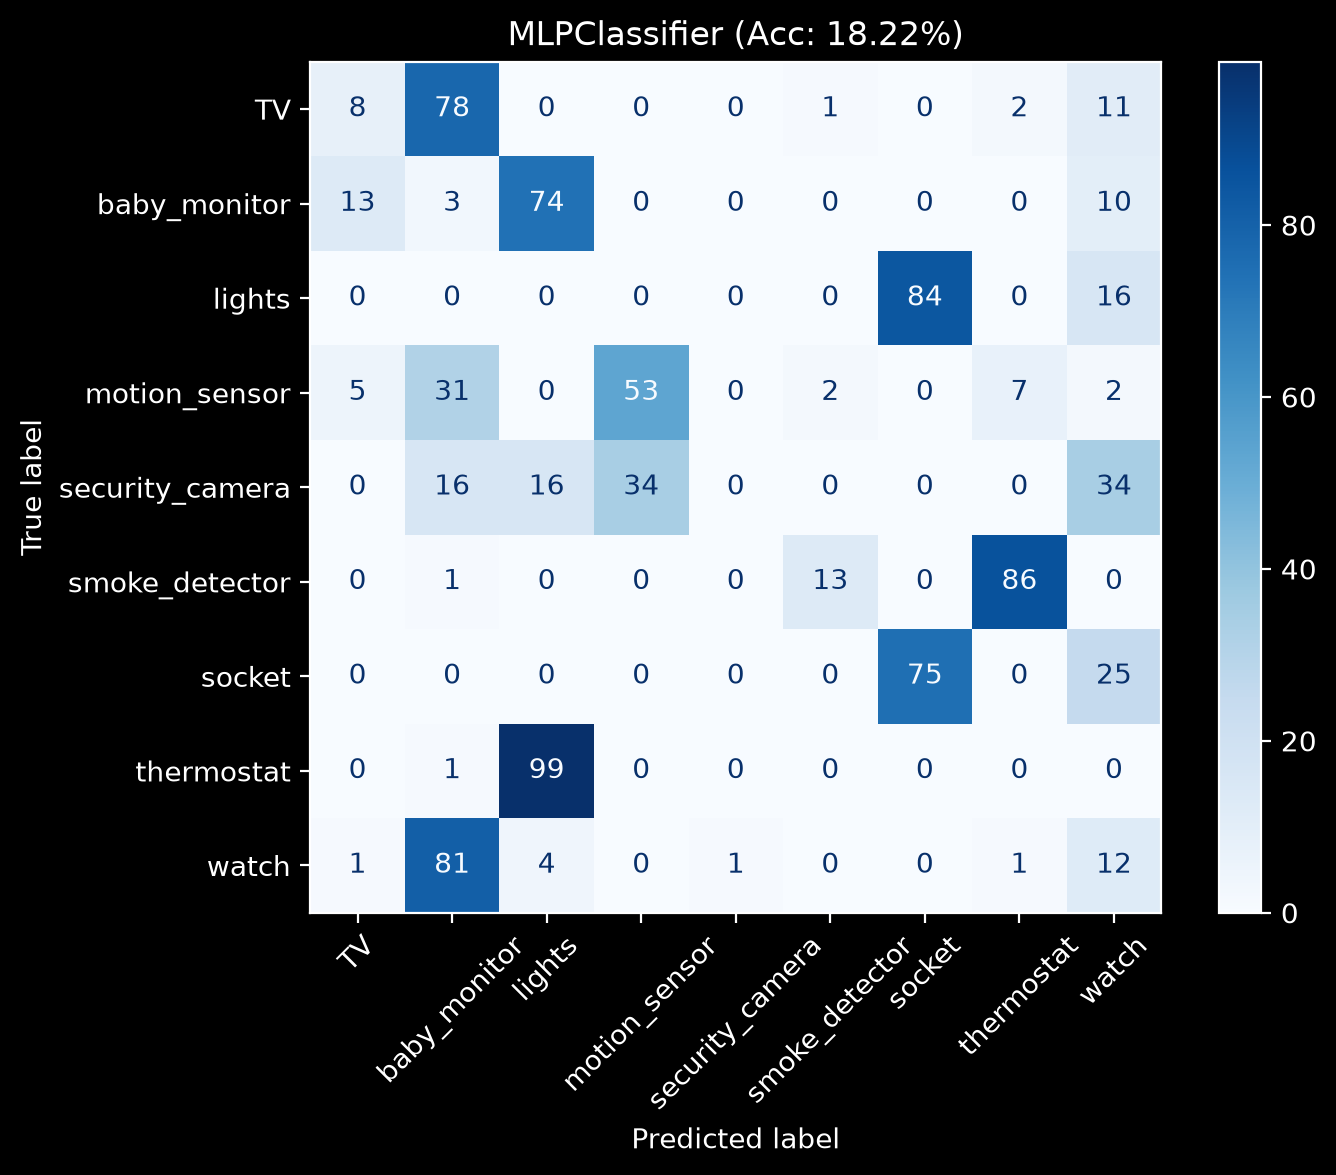

In [ ]:
# standardize features for the neural network using training statistics
nn_scaler = StandardScaler()
X_train_nn = nn_scaler.fit_transform(X_train)
X_report_nn = nn_scaler.transform(X_report)

# nine combinations of hidden units (32, 64, 128) and hidden layers (1, 2, 3)
mlp_param_grid = {
    "hidden_layer_sizes": [
        (32,),
        (64,),
        (128,),
        (32, 32),
        (64, 64),
        (128, 128),
        (32, 32, 32),
        (64, 64, 64),
        (128, 128, 128),
    ]
}

# optimize mlpclassifier with early stopping and up to 300 epochs
t0_mlp = time()
mlp_search = GridSearchCV(
    MLPClassifier(max_iter=300, early_stopping=True, random_state=42),
    mlp_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
)
mlp_search.fit(X_train_nn, y_train)
mlp_time_min = (time() - t0_mlp) / 60.0

# evaluate on reporting set
mlp_pred = mlp_search.predict(X_report_nn)
mlp_acc = accuracy_score(y_report, mlp_pred)

print(f"MLP best params: {mlp_search.best_params_}")
print(f"MLP CV accuracy: {mlp_search.best_score_:.4f}")
print(f"MLP reporting accuracy: {mlp_acc:.4f}")
print(f"MLP search time: {mlp_time_min:.2f} minutes")

fig_mlp, ax_mlp = plt.subplots(figsize=(7.5, 6))
ConfusionMatrixDisplay.from_predictions(
    y_report,
    mlp_pred,
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax_mlp,
)
ax_mlp.set_title(f"MLPClassifier (Acc: {mlp_acc:.2%})")
plt.tight_layout()
plt.show()

Tuning `MLPClassifier` across the nine architectures took 0.03 minutes and picked `hidden_layer_sizes=(32, 32)` with an 84.44% 5-fold CV score, but reporting accuracy collapsed to 18.22%. That 18.22% still beats the 11.11% random baseline, yet it lags roughly 50 percentage points behind all three tree ensembles (67.78% to 71.00%). The reason for that crash is a huge scale shift in cumulative traffic columns between the two CSV files: in `X_train`, `bytes` maxes out at `1,213` and `http_time_var` is `0`, whereas `X_report` contains long captures where `bytes` hits `2.14e8` and `http_time_var` reaches `2.31e18`. Even after `StandardScaler`, those reporting outliers sit up to `2.31e18` standard deviations above the training mean. Because a neural network multiplies inputs by dense weight matrices in every layer, one giant feature value blows up the hidden units and causes 0% recall on `thermostat`, `lights`, and `security_camera`. Tree splits ($x_j \le t$) only check which side of a threshold a number falls on, so extreme reporting values follow the normal high-value branch without wrecking the prediction.

As for complexity and interpretability, our `(32, 32)` network blends all 297 inputs across `10,816` dense weights and ReLU activations, so it behaves like a black box with no built-in feature ranking. Decision tree ensembles split on one variable at a time and expose `feature_importances_` directly from impurity reductions, which makes it easy to see that TTL and inter-arrival columns drive their predictions.

## Part 5: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

Our main inefficiency in this lab came from inconsistent target variables and cross-validation setups when we split up the early sections. One person encoded `device_category` with `LabelEncoder` in Part 1 but accidentally returned the raw string Series, and another teammate started Part 2 with manual `for` loops using `random_state=0` instead of a shared `GridSearchCV` object. Because of this mismatch, our initial runs didn't use the same fold splits and couldn't be compared fairly across all four model sections. We fixed the issue by returning the integer target arrays from Part 1 and sharing one `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` object across every `GridSearchCV` call, and next lab we'll write down shared variable names and CV settings before coding separate parts.